In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
import sys

sys.path.append("../..")

import json
import time
from pathlib import Path

import dask
import numpy as np
from numpy.polynomial.polynomial import Polynomial
import pandas as pd
import xarray as xr
from dask.diagnostics import ProgressBar

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid", {"grid.color": ".93"})

from src.data_processing.load_data import ClimateReanalysisData, ClimateModelData
from src.utils.constants import REFERENCE_PERIOD, BC_SUBDAILY_CHUNKS
from src.conversion_energy.wind import extrapolate_wind_speed
from src.utils.utils_xarray import tile_dataset_to_target_time

In [4]:
import os

os.environ["OMP_NUM_THREADS"] = "1"  # OpenMP
os.environ["MKL_NUM_THREADS"] = "1"  # MKL
os.environ["OPENBLAS_NUM_THREADS"] = "1"  # OpenBLAS
os.environ["NUMEXPR_NUM_THREADS"] = "1"  # numexpr

dask.config.set(num_workers=15, threads_per_worker=16)
dask.config.set(
    {
        "distributed.worker.memory.target": 0.7,
        "distributed.worker.memory.spill": 0.8,
        "distributed.worker.memory.pause": 0.9,
        "array.chunk-size": "512MiB",
        "logging.distributed": "error",
    }
)

In [5]:
with open("../../paths_so4.json") as f:
    paths = json.load(f)

path_data_cerra = Path(paths["path_data_cerra"])
path_data_processed = Path(paths["path_data_processed"])
path_figs = Path("../../figs")
(path_figs / "wind_speed_alpha").mkdir(parents=True, exist_ok=True)

ws_cerra_path = path_data_processed / "cerra_processed" / "regridded" / "ws.zarr"
ws_10m_cerra_path = path_data_processed / "cerra_processed" / "regridded" / "10si.zarr"
ws_alpha_cerra_path = path_data_processed / "cerra_processed" / "alpha"

In [6]:
ds_ws = ClimateReanalysisData(
    ws_cerra_path,
    chunks="auto",
    extent=None,
    load=False,
    drop_leap_days=True,
)
ds_ws.ds_data = ds_ws.ds_data.sel(time=slice(*REFERENCE_PERIOD))

ds_ws_10m = ClimateReanalysisData(
    ws_10m_cerra_path,
    chunks="auto",
    extent=None,
    load=False,
    drop_leap_days=True,
)
ds_ws_10m.ds_data = ds_ws_10m.ds_data.sel(time=slice(*REFERENCE_PERIOD)).rename(
    {"10si": "ws"}
)

In [7]:
heights = [10, 100]

da_alpha_cerra = xr.open_dataset(
    ws_alpha_cerra_path / f"da_alpha_cerra_heights_{heights[0]}_{heights[1]}.nc"
)
da_alpha_temp_smoothed_cerra = xr.open_dataset(
    ws_alpha_cerra_path
    / f"da_alpha_temp_smoothed_cerra_heights_{heights[0]}_{heights[1]}.nc"
)
da_alpha_tempspatial_smoothed_cerra = xr.open_dataset(
    ws_alpha_cerra_path
    / f"da_alpha_tempspatial_smoothed_cerra_heights_{heights[0]}_{heights[1]}.nc"
)

da_alpha_cerra_median = xr.open_dataset(
    ws_alpha_cerra_path / f"da_alpha_cerra_median_heights_{heights[0]}_{heights[1]}.nc"
)

In [8]:
# Index da_alpha cyclically
da_alpha_tiled = (
    da_alpha_tempspatial_smoothed_cerra
    .isel(
        time=(
            np.arange(len(ds_ws.ds_data.time))
            % len(da_alpha_tempspatial_smoothed_cerra.time)
        )
    )
    .assign_coords(time=ds_ws.ds_data.time)
)

# Log-linear alpha computation

## Test on one grid cell, one day

In [10]:
ws_cerra_path = path_data_processed / "cerra_processed" / "regridded" / "ws.zarr"
ws_10m_cerra_path = (
    path_data_processed / "cerra_processed" / "regridded" / "10si.zarr"
)
ds_ws_cerra = xr.open_zarr(ws_cerra_path, chunks="auto")
ds_ws_10m_cerra = xr.open_zarr(ws_10m_cerra_path, chunks="auto")

In [11]:
da_ws_100 = ds_ws_cerra["ws"].sel(height=100, lat=47.5, lon=8.5, method="nearest")
jan1_ws_100 = da_ws_100.sel(time=(da_ws_100.time.dt.month == 1) & (da_ws_100.time.dt.day == 1))

da_ws_10 = ds_ws_10m_cerra["10si"].sel(lat=47.5, lon=8.5, method="nearest")
jan1_ws_10 = da_ws_10.sel(time=(da_ws_10.time.dt.month == 1) & (da_ws_10.time.dt.day == 1))

In [19]:
def fit_log_linear_ws(da_low, da_high, log_transform=True):
    """
    Fit linear model: log(da_high) = intercept + slope * log(da_low)
    Aligns on time, drops missing values and returns fit stats and cleaned arrays.

    Returns: intercept, slope, r2, mse, bias, x_clean, y_clean
    """
    # align on time and drop missing values
    da_low_a, da_high_a = xr.align(da_low, da_high, join="inner")
    if log_transform:
        x = np.log(da_low_a.values.ravel())
        y = np.log(da_high_a.values.ravel())
    else:
        x = da_low_a.values.ravel()
        y = da_high_a.values.ravel()

    mask = np.isfinite(x) & np.isfinite(y)
    x_clean = x[mask]
    y_clean = y[mask]

    # fit linear model y = intercept + slope * x
    intercept, slope = Polynomial.fit(x_clean, y_clean, 1).convert()
    # slope, intercept = np.polyfit(x_clean, y_clean, 1)

    # compute R^2, MSE and bias
    y_pred = intercept + slope * x_clean
    ss_res = np.sum((y_clean - y_pred) ** 2)
    ss_tot = np.sum((y_clean - y_clean.mean()) ** 2)
    r2 = 1 - ss_res / ss_tot if ss_tot != 0 else np.nan
    mse = np.mean((y_clean - y_pred) ** 2)
    bias = np.mean(y_clean - y_pred)

    print(f"intercept: {intercept:.6f}, slope: {slope:.6f}, R²: {r2:.4f}, MSE: {mse:.6f}, Bias: {bias:.6f}")

    return intercept, slope, r2, mse, bias, x_clean, y_clean


In [18]:
intercept_h, slope_h, r2_h, mse_h, bias_h, x_clean_h, y_clean_h = fit_log_linear_ws(
    jan1_ws_10, jan1_ws_100, log_transform=True
)

intercept: 0.851386, slope: 0.745958, R²: 0.5140, MSE: 0.307126, Bias: -0.000000


Fitting hour 0


intercept: 0.773587, slope: 0.730098, R²: 0.3605, MSE: 0.630850, Bias: 0.000000
Fitting hour 3
intercept: 0.981210, slope: 0.584795, R²: 0.2777, MSE: 0.613779, Bias: 0.000000
Fitting hour 6
intercept: 1.050637, slope: 0.605817, R²: 0.6297, MSE: 0.142485, Bias: -0.000000
Fitting hour 9
intercept: 0.957247, slope: 0.594597, R²: 0.3997, MSE: 0.355331, Bias: -0.000000
Fitting hour 12
intercept: 0.544915, slope: 1.098952, R²: 0.9123, MSE: 0.057666, Bias: 0.000000
Fitting hour 15
intercept: 0.770836, slope: 0.866460, R²: 0.8605, MSE: 0.060433, Bias: -0.000000
Fitting hour 18
intercept: 0.809818, slope: 0.817933, R²: 0.6368, MSE: 0.152922, Bias: 0.000000
Fitting hour 21
intercept: 0.739366, slope: 0.877835, R²: 0.5777, MSE: 0.268084, Bias: 0.000000


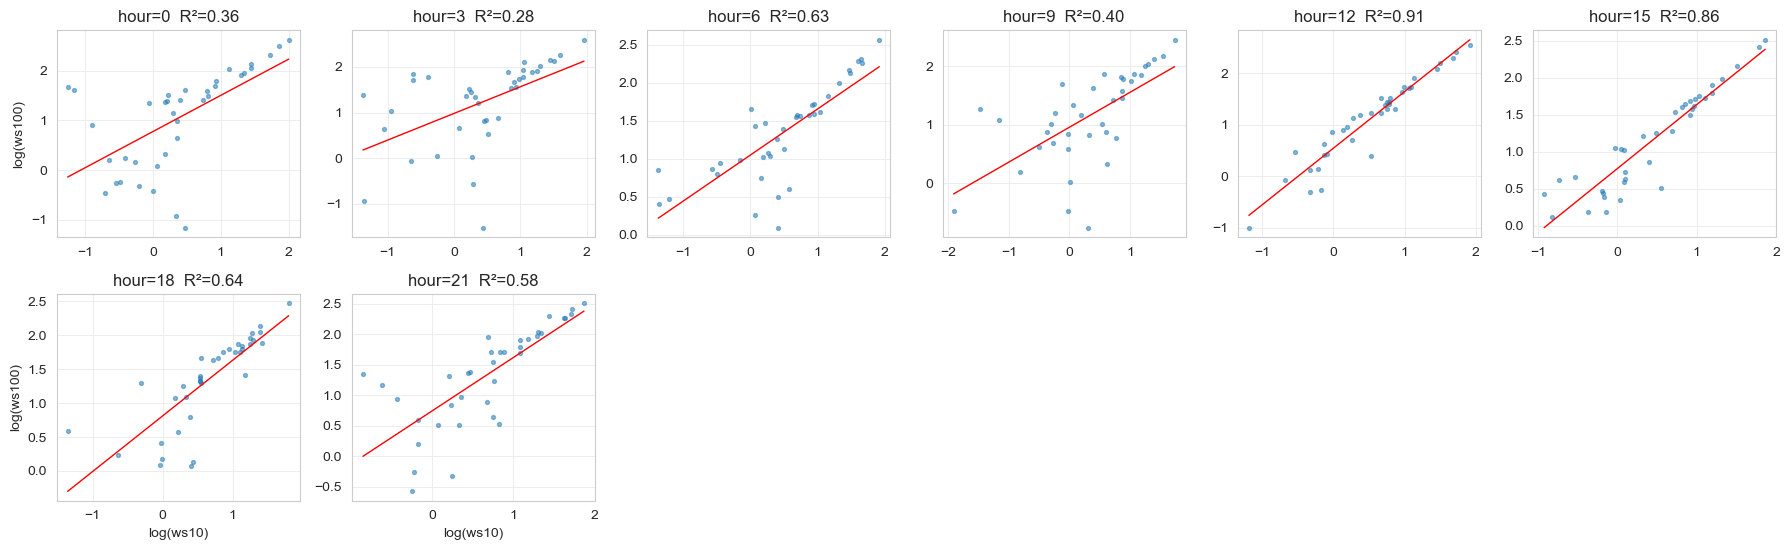

In [20]:
# call the function for the January 1st datasets
# fit per-hour and plot subplots
hours = np.unique(jan1_ws_10.time.dt.hour.values)
n = len(hours)
cols = 6
rows = int(np.ceil(n / cols))

fig, axes = plt.subplots(rows, cols, figsize=(cols * 3, rows * 2.8), squeeze=False)
axes_flat = axes.ravel()
intercepts = []
slopes = []

for i, h in enumerate(hours):
    sel10 = jan1_ws_10.sel(time=jan1_ws_10.time.dt.hour == int(h))
    sel100 = jan1_ws_100.sel(time=jan1_ws_100.time.dt.hour == int(h))

    # fit
    print(f"Fitting hour {int(h)}")
    intercept_h, slope_h, r2_h, mse_h, bias_h, x_clean_h, y_clean_h = fit_log_linear_ws(
        sel10, sel100, log_transform=True
    )
    intercepts.append(intercept_h)
    slopes.append(slope_h)
    axh = axes_flat[i]
    axh.scatter(x_clean_h, y_clean_h, s=8, alpha=0.5)
    xs = np.linspace(np.nanmin(x_clean_h), np.nanmax(x_clean_h), 200)
    axh.plot(xs, intercept_h + slope_h * xs, color="red", linewidth=1)
    axh.set_title(f"hour={int(h)}  R²={r2_h:.2f}")
    # only label left column and bottom row
    row_idx = i // cols
    col_idx = i % cols
    if col_idx == 0:
        axh.set_ylabel("log(ws100)")
    if row_idx == rows - 1:
        axh.set_xlabel("log(ws10)")

# hide any empty subplots
for j in range(n, rows * cols):
    axes_flat[j].axis("off")

fig.tight_layout()
plt.show()

In [21]:
[slope / np.log(100 / 10) for slope in slopes]

[0.3170777415552334,
 0.25397326811161053,
 0.26310312265834085,
 0.25823006430031753,
 0.4772687210855967,
 0.3762987183794327,
 0.355223641285422,
 0.38123876310034593]

In [22]:
slope_h / np.log(100 / 10)

0.38123876310034593

In [23]:
da_alpha_cerra["alpha"].sel(lat=47.5, lon=8.5, method="nearest").sel(time=(da_alpha_cerra.time.dt.month == 1) & (da_alpha_cerra.time.dt.day == 1)).values

array([0.3294385 , 0.38693395, 0.38778827, 0.3843154 , 0.2620776 ,
       0.31550986, 0.3107325 , 0.31957033], dtype=float32)

## Validation on climate data

In [9]:
climate_model_chain = "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1"
climate_scenario = "rcp85"
climate_model_bc_path = (
        path_data_processed
        / "cordex_processed"
        / f"{climate_model_chain}_{climate_scenario}"
        / "bias_corrected"
        / "3hr"
    )

ds_sfcWind_climate_model = ClimateModelData(
    climate_model_bc_path / "sfcWind.zarr",
    chunks="auto",
    extent=None,
    load=False,
    drop_leap_days=True,
)
ds_sfcWind_climate_model.ds_data = ds_sfcWind_climate_model.ds_data.rename(
    {"sfcWind": "ws"}
).sel(time=slice("2021", "2030"))

ds_ws_100m_climate_model = ClimateModelData(
    climate_model_bc_path / "wind100m.zarr",
    chunks="auto",
    extent=None,
    load=False,
    drop_leap_days=True,
)

ds_ws_100m_climate_model.ds_data = ds_ws_100m_climate_model.ds_data.rename(
    {"wind100m": "ws"}
).sel(time=slice("2021", "2030"))

In [10]:
# Index da_alpha cyclically
da_alpha_cerra_tiled = (
    da_alpha_cerra
    .isel(
        time=(
            np.arange(len(ds_ws_100m_climate_model.ds_data.time))
            % len(da_alpha_cerra.time)
        )
    )
    .assign_coords(time=ds_ws_100m_climate_model.ds_data.time)
).chunk(BC_SUBDAILY_CHUNKS)

In [11]:
# Index da_alpha cyclically
da_alpha_temp_smoothed_cerra_tiled = (
    da_alpha_temp_smoothed_cerra
    .isel(
        time=(
            np.arange(len(ds_ws_100m_climate_model.ds_data.time))
            % len(da_alpha_temp_smoothed_cerra.time)
        )
    )
    .assign_coords(time=ds_ws_100m_climate_model.ds_data.time)
).chunk(BC_SUBDAILY_CHUNKS)

In [ ]:
# Index da_alpha cyclically
da_alpha_temp_smoothed_cerra_tiled = (
    da_alpha_temp_smoothed_cerra
    .isel(
        time=(
            np.arange(len(ds_ws_100m_climate_model.ds_data.time))
            % len(da_alpha_temp_smoothed_cerra.time)
        )
    )
    .assign_coords(time=ds_ws_100m_climate_model.ds_data.time)
).chunk(BC_SUBDAILY_CHUNKS)

In [28]:
da_ws_100_climate_model = ds_ws_100m_climate_model.ds_data["ws"].sel(lat=47.5, lon=8.5, method="nearest")
jan1_ws_100_climate_model = da_ws_100_climate_model.sel(time=(da_ws_100_climate_model.time.dt.month == 1) & (da_ws_100_climate_model.time.dt.day == 1))

da_ws_10_climate_model = ds_sfcWind_climate_model.ds_data["ws"].sel(lat=47.5, lon=8.5, method="nearest")
jan1_ws_10_climate_model = da_ws_10_climate_model.sel(time=(da_ws_10_climate_model.time.dt.month == 1) & (da_ws_10_climate_model.time.dt.day == 1))

In [41]:
y_true = jan1_ws_100_climate_model.sel(time=(jan1_ws_100_climate_model.time.dt.hour == 0)).values

In [57]:
with ProgressBar(dt=1):
    y_pred_climate_model_old_alpha = jan1_ws_10_climate_model * (100 / 10) ** da_alpha_temp_smoothed_cerra_tiled.alpha.sel(lat=47.5, lon=8.5, method="nearest").sel(time=jan1_ws_10_climate_model.time).compute()
for i, hour in enumerate(hours):
    print(f"Evaluating hour {int(hour)}")
    y_true = jan1_ws_100_climate_model.sel(time=(jan1_ws_100_climate_model.time.dt.hour == hour)).values
    with ProgressBar(dt=1):
        y_pred_climate_model = np.exp(np.log(jan1_ws_10_climate_model.sel(time=(jan1_ws_100_climate_model.time.dt.hour == hour))) * slopes[i] + intercepts[i]).compute()
    ss_res = np.sum((y_true - y_pred_climate_model) ** 2)
    ss_tot = np.sum((y_true - y_true.mean()) ** 2)
    r2 = 1 - ss_res / ss_tot if ss_tot != 0 else np.nan
    mse = np.mean((y_true - y_pred_climate_model) ** 2)
    bias = np.mean(y_true - y_pred_climate_model)

    print(f"Log-Linear regression: R²: {r2:.4f}, MSE: {mse:.6f}, Bias: {bias:.6f}")

    y_pred_climate_model_old_alpha_hour = y_pred_climate_model_old_alpha.sel(time=(jan1_ws_100_climate_model.time.dt.hour == hour)).values
    ss_res = np.sum((y_true - y_pred_climate_model_old_alpha_hour) ** 2)
    ss_tot = np.sum((y_true - y_true.mean()) ** 2)
    r2 = 1 - ss_res / ss_tot if ss_tot != 0 else np.nan
    mse = np.mean((y_true - y_pred_climate_model_old_alpha_hour) ** 2)
    bias = np.mean(y_true - y_pred_climate_model_old_alpha_hour)

    print(f"Power law: R²: {r2:.4f}, MSE: {mse:.6f}, Bias: {bias:.6f}")
    print("-----\n")

[                                        ] | 0% Completed | 200.05 us

[########################################] | 100% Completed | 9.01 s
Evaluating hour 0
[########################################] | 100% Completed | 3.01 ss
Log-Linear regression: R²: 0.7702, MSE: 2.901709, Bias: 0.997404
Power law: R²: 0.9493, MSE: 0.640086, Bias: -0.268084
-----

Evaluating hour 3
[########################################] | 100% Completed | 1.00 ss
Log-Linear regression: R²: 0.7405, MSE: 2.756978, Bias: 0.465971
Power law: R²: 0.9387, MSE: 0.651181, Bias: -0.642405
-----

Evaluating hour 6
[########################################] | 100% Completed | 1.00 ss
Log-Linear regression: R²: 0.7683, MSE: 2.312908, Bias: 0.235603
Power law: R²: 0.8844, MSE: 1.153643, Bias: -0.413326
-----

Evaluating hour 9
[########################################] | 100% Completed | 1.00 ss
Log-Linear regression: R²: 0.7398, MSE: 1.632975, Bias: 0.468305
Power law: R²: 0.9097, MSE: 0.567077, Bias: -0.116771
-----

Evaluating hour 12
[########################################] | 100% Comple

In [58]:
def calc_metrics(y, yhat):
    bias = np.mean(y - yhat)
    mse = np.mean((y - yhat) ** 2)
    rmse = np.sqrt(mse)
    ss_res = np.sum((y - yhat) ** 2)
    ss_tot = np.sum((y - y.mean()) ** 2)
    r2 = 1 - ss_res / ss_tot if ss_tot != 0 else np.nan
    return bias, mse, rmse, r2

In [60]:
for hour in hours:
    print(f"Evaluating linear bias correction for hour {int(hour)}")
    # Fit linear bias correction y_true = m * y_pred + c on the hourly arrays
    y_pred_old = np.asarray(y_pred_climate_model_old_alpha.sel(time=(jan1_ws_100_climate_model.time.dt.hour == hour)).values)
    y_true_arr = np.asarray(jan1_ws_100_climate_model.sel(time=(jan1_ws_100_climate_model.time.dt.hour == hour)).values)

    # fit slope (m) and intercept (c)
    m, c = np.polyfit(y_pred_old, y_true_arr, 1)

    # apply correction
    y_pred_corrected = m * y_pred_old + c

    # metrics
    bias_before, mse_before, rmse_before, r2_before = calc_metrics(y_true_arr, y_pred_old)
    bias_after, mse_after, rmse_after, r2_after = calc_metrics(y_true_arr, y_pred_corrected)

    print(f"Linear fit: slope={m:.6f}, intercept={c:.6f}")
    print(f"Before correction: bias={bias_before:.6f}, MSE={mse_before:.6f}, RMSE={rmse_before:.6f}, R²={r2_before:.4f}")
    print(f"After correction:  bias={bias_after:.6f}, MSE={mse_after:.6f}, RMSE={rmse_after:.6f}, R²={r2_after:.4f}")

Evaluating linear bias correction for hour 0
Linear fit: slope=0.882673, intercept=0.329387
Before correction: bias=-0.268084, MSE=0.640086, RMSE=0.800054, R²=0.9493
After correction:  bias=0.000000, MSE=0.351282, RMSE=0.592690, R²=0.9722
Evaluating linear bias correction for hour 3
Linear fit: slope=0.891897, intercept=-0.055505
Before correction: bias=-0.642405, MSE=0.651181, RMSE=0.806958, R²=0.9387
After correction:  bias=0.000000, MSE=0.083662, RMSE=0.289245, R²=0.9921
Evaluating linear bias correction for hour 6
Linear fit: slope=0.900554, intercept=0.120964
Before correction: bias=-0.413326, MSE=1.153643, RMSE=1.074078, R²=0.8844
After correction:  bias=-0.000000, MSE=0.871729, RMSE=0.933664, R²=0.9127
Evaluating linear bias correction for hour 9
Linear fit: slope=0.889701, intercept=0.361570
Before correction: bias=-0.116771, MSE=0.567077, RMSE=0.753045, R²=0.9097
After correction:  bias=0.000000, MSE=0.464107, RMSE=0.681254, R²=0.9261
Evaluating linear bias correction for hour

# Comparison of the different alphas

## First timestep

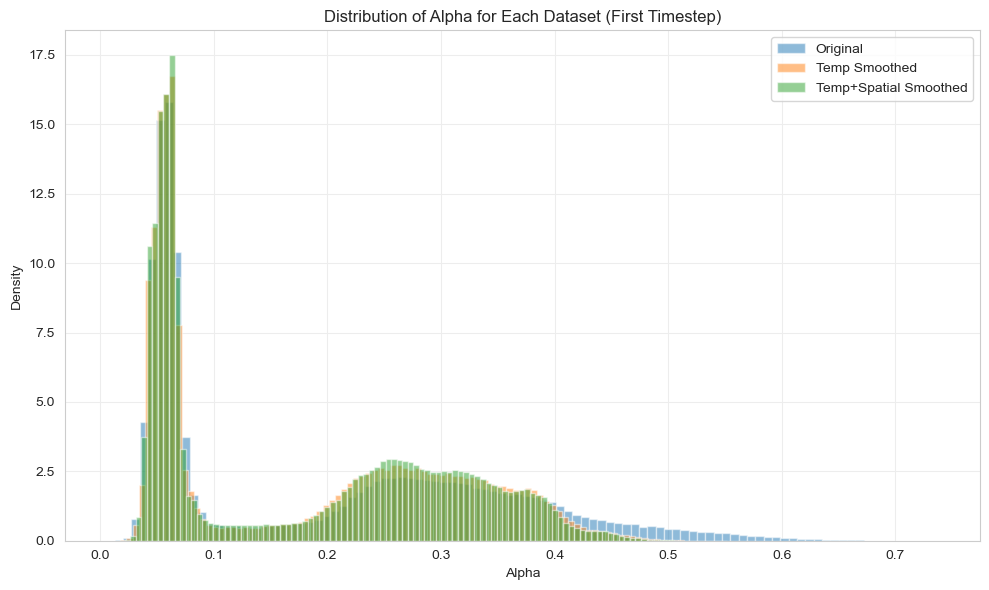

In [6]:
# Extract alpha values for the first timestep and flatten
alpha_samples = {
    "Original": da_alpha_cerra.alpha.isel(time=0).values.ravel(),
    "Temp Smoothed": da_alpha_temp_smoothed_cerra.alpha.isel(time=0).values.ravel(),
    "Temp+Spatial Smoothed": da_alpha_tempspatial_smoothed_cerra.alpha.isel(
        time=0
    ).values.ravel(),
}

plt.figure(figsize=(10, 6))
for label, data in alpha_samples.items():
    plt.hist(data, bins=100, alpha=0.5, label=label, density=True)

plt.xlabel("Alpha")
plt.ylabel("Density")
plt.title("Distribution of Alpha for Each Dataset (First Timestep)")
plt.legend()
plt.tight_layout()
plt.show()

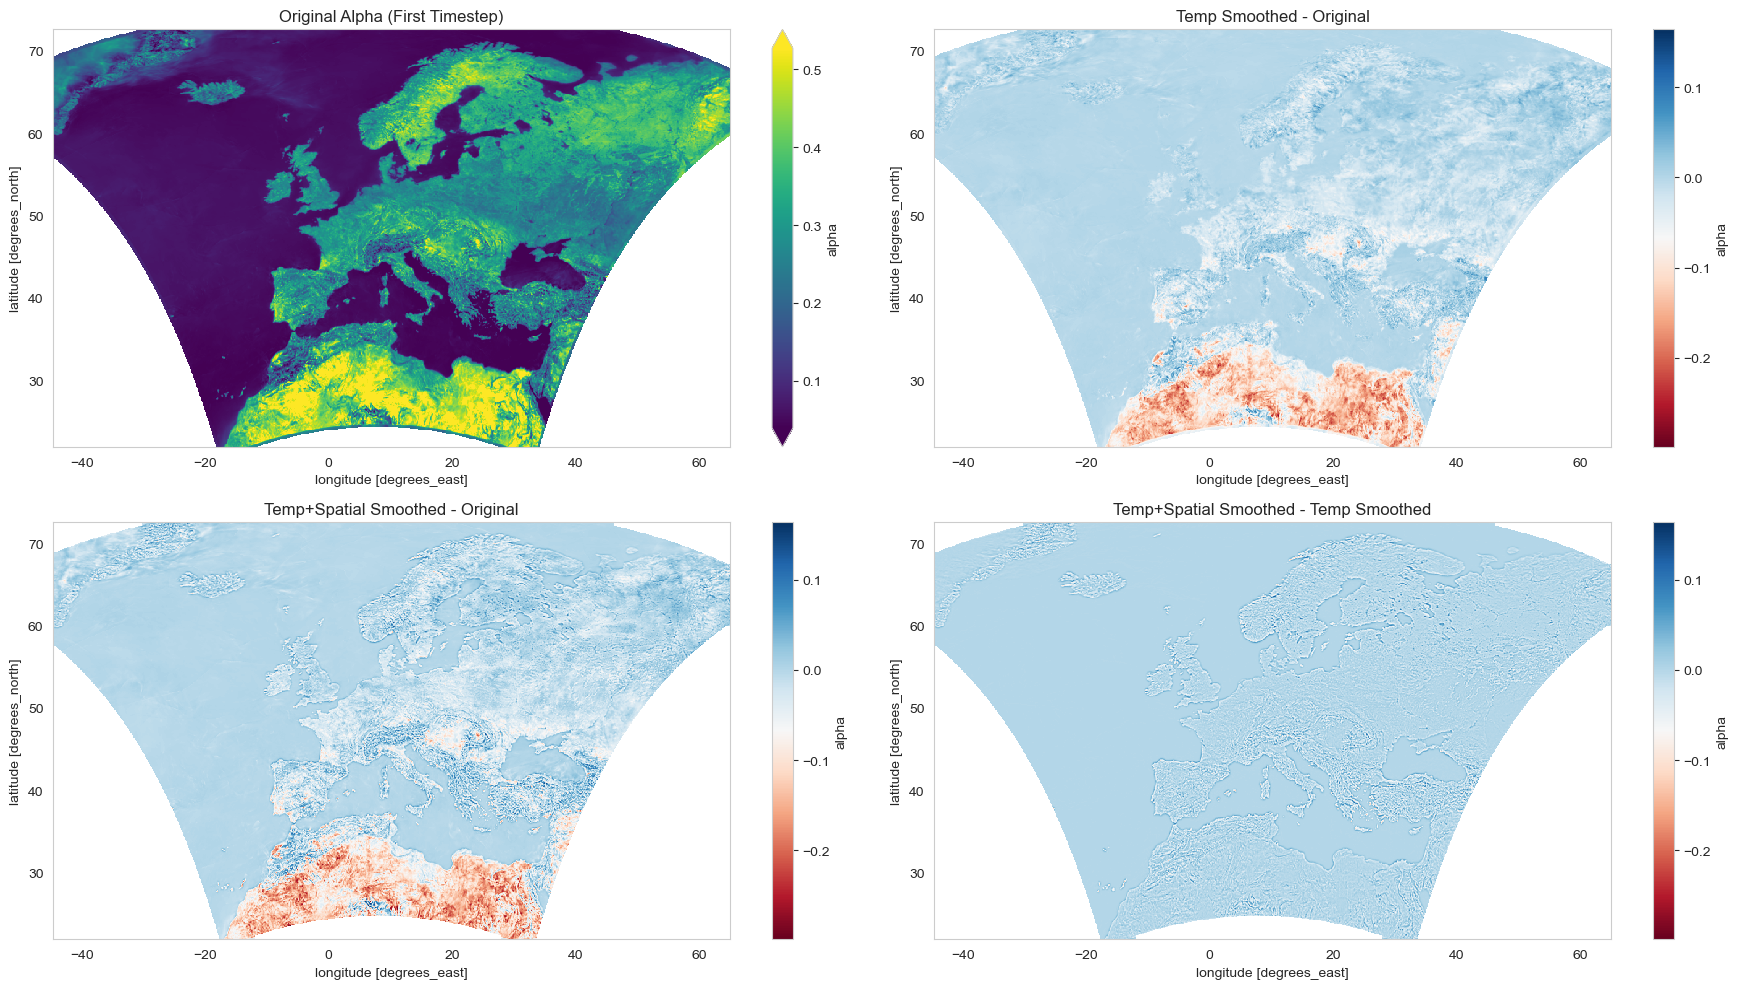

In [ ]:
# Plot the map of the original alpha (first timestep)
fig, axes = plt.subplots(2, 2, figsize=(18, 10))
axes = axes.flatten()

# Original alpha
da_alpha_cerra.alpha.isel(time=0).plot(ax=axes[0], cmap="viridis", robust=True)
axes[0].set_title("Original Alpha (First Timestep)")

# Compute differences
diff_temp = da_alpha_temp_smoothed_cerra.alpha.isel(time=0) - da_alpha_cerra.alpha.isel(
    time=0
)
diff_tempspatial = da_alpha_tempspatial_smoothed_cerra.alpha.isel(
    time=0
) - da_alpha_cerra.alpha.isel(time=0)
diff_tempspatial_temp = da_alpha_tempspatial_smoothed_cerra.alpha.isel(
    time=0
) - da_alpha_temp_smoothed_cerra.alpha.isel(time=0)

# Find common vmin/vmax for all difference plots
vmin = min(
    diff.min().item() for diff in [diff_temp, diff_tempspatial, diff_tempspatial_temp]
)
vmax = max(
    diff.max().item() for diff in [diff_temp, diff_tempspatial, diff_tempspatial_temp]
)

# Plot differences with shared colorbar
im1 = diff_temp.plot(
    ax=axes[1], cmap="RdBu", robust=True, vmin=vmin, vmax=vmax, add_colorbar=True
)
axes[1].set_title("Temp Smoothed - Original")

im2 = diff_tempspatial.plot(
    ax=axes[2], cmap="RdBu", robust=True, vmin=vmin, vmax=vmax, add_colorbar=True
)
axes[2].set_title("Temp+Spatial Smoothed - Original")

im3 = diff_tempspatial_temp.plot(
    ax=axes[3], cmap="RdBu", robust=True, vmin=vmin, vmax=vmax, add_colorbar=True
)
axes[3].set_title("Temp+Spatial Smoothed - Temp Smoothed")

plt.tight_layout()
plt.show()

## General analysis

### Variability

In [ ]:
# Temporal variability: standard deviation over time for each grid point
temporal_std = {
    "Original": da_alpha_cerra.alpha.std(dim="time"),
    "Temp Smoothed": da_alpha_temp_smoothed_cerra.alpha.std(dim="time"),
    "Temp+Spatial Smoothed": da_alpha_tempspatial_smoothed_cerra.alpha.std(dim="time"),
}

# Spatial variability: standard deviation over space for each timestep
spatial_std = {
    "Original": da_alpha_cerra.alpha.std(dim=["lat", "lon"]),
    "Temp Smoothed": da_alpha_temp_smoothed_cerra.alpha.std(dim=["lat", "lon"]),
    "Temp+Spatial Smoothed": da_alpha_tempspatial_smoothed_cerra.alpha.std(
        dim=["lat", "lon"]
    ),
}

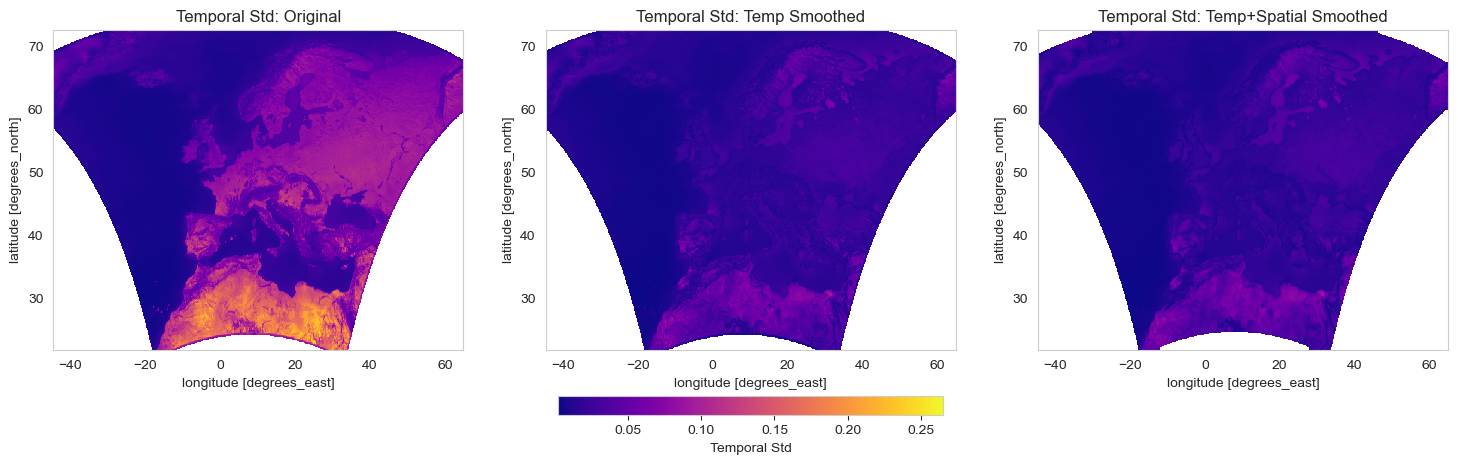

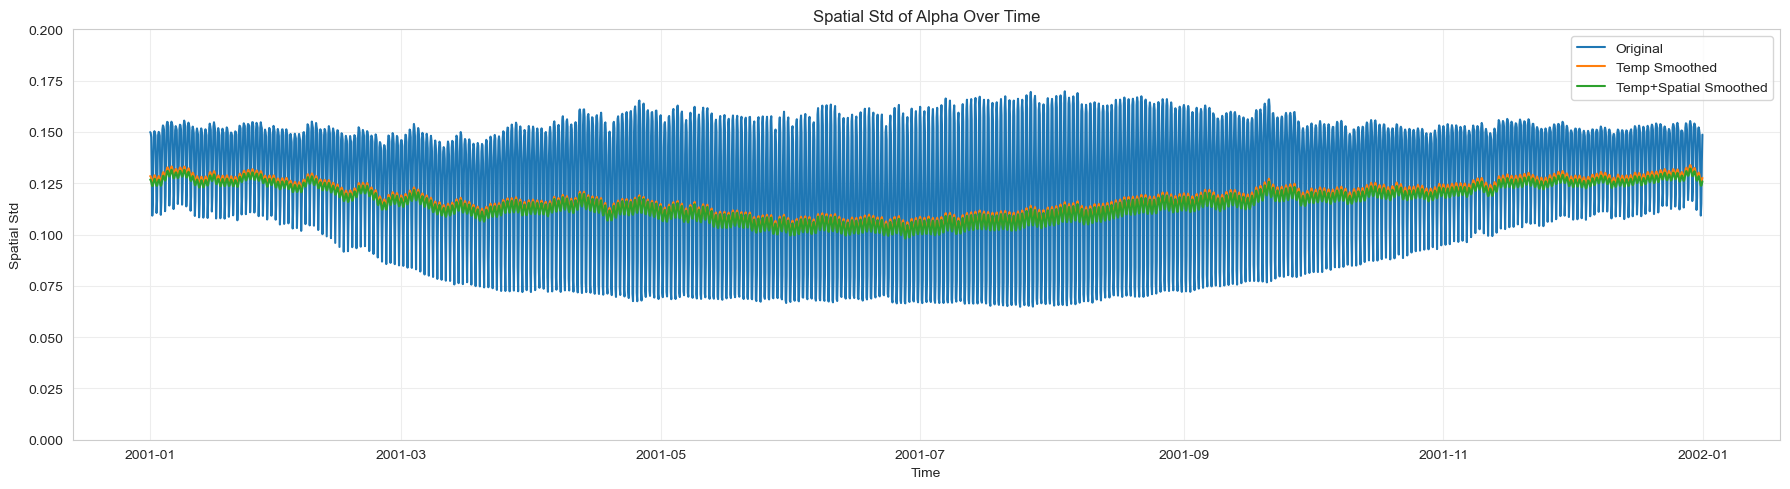

In [ ]:
# Plot temporal std maps for each dataset with a shared colorbar and same value range
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
vmin = min(std_map.min().item() for std_map in temporal_std.values())
vmax = max(std_map.max().item() for std_map in temporal_std.values())

im_list = []
for ax, (label, std_map) in zip(axes, temporal_std.items()):
    im = std_map.plot(
        ax=ax, cmap="plasma", robust=True, vmin=vmin, vmax=vmax, add_colorbar=False
    )
    ax.set_title(f"Temporal Std: {label}")
    im_list.append(im)

# Add a single colorbar for all subplots, place it below the subplots (horizontal)
cbar = fig.colorbar(
    im_list[0], ax=axes, orientation="horizontal", fraction=0.05, pad=0.12
)
cbar.set_label("Temporal Std")

# plt.tight_layout(rect=[0, 0.08, 1, 1])
plt.savefig(
    path_figs / "wind_speed_alpha" / "temporal_std_alpha.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

# Plot spatial std time series for each dataset
plt.figure(figsize=(18, 5))
for label, std_ts in spatial_std.items():
    plt.plot(da_alpha_cerra.time, std_ts, label=label)
plt.xlabel("Time")
plt.ylabel("Spatial Std")
plt.ylim(0, 0.2)
plt.title("Spatial Std of Alpha Over Time")
plt.legend()
plt.tight_layout()
plt.savefig(
    path_figs / "wind_speed_alpha" / "spatial_std_alpha.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

### Mean

In [ ]:
# Compute spatial mean (mean over time for each grid point)
spatial_mean = {
    "Original": da_alpha_cerra.alpha.mean(dim="time"),
    "Temp Smoothed": da_alpha_temp_smoothed_cerra.alpha.mean(dim="time"),
    "Temp+Spatial Smoothed": da_alpha_tempspatial_smoothed_cerra.alpha.mean(dim="time"),
}

# Compute temporal mean (mean over space for each timestep)
temporal_mean = {
    "Original": da_alpha_cerra.alpha.mean(dim=["lat", "lon"]),
    "Temp Smoothed": da_alpha_temp_smoothed_cerra.alpha.mean(dim=["lat", "lon"]),
    "Temp+Spatial Smoothed": da_alpha_tempspatial_smoothed_cerra.alpha.mean(
        dim=["lat", "lon"]
    ),
}

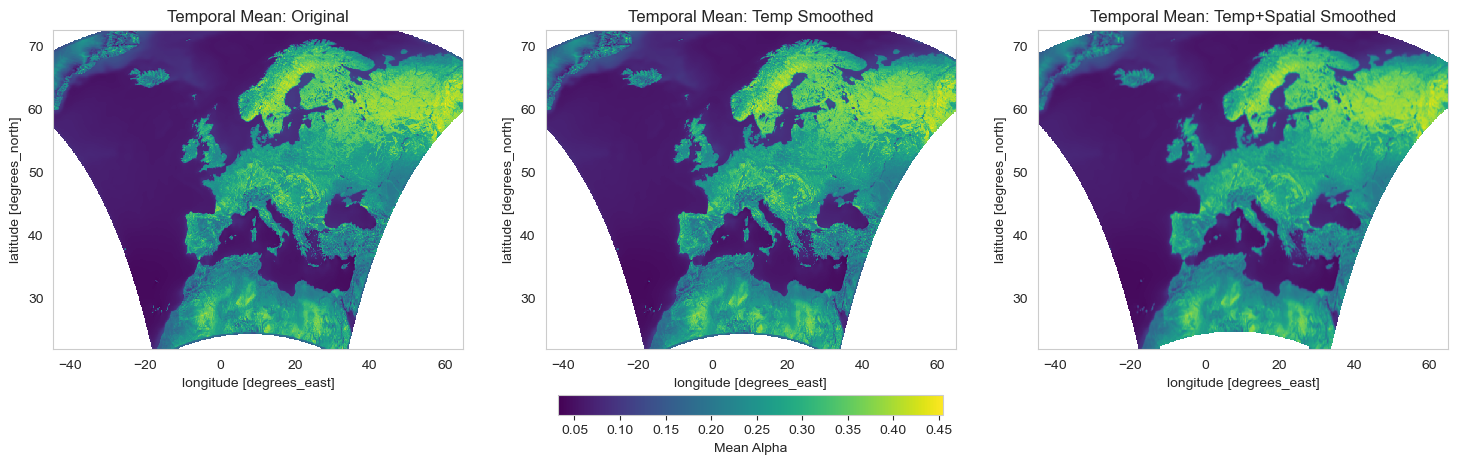

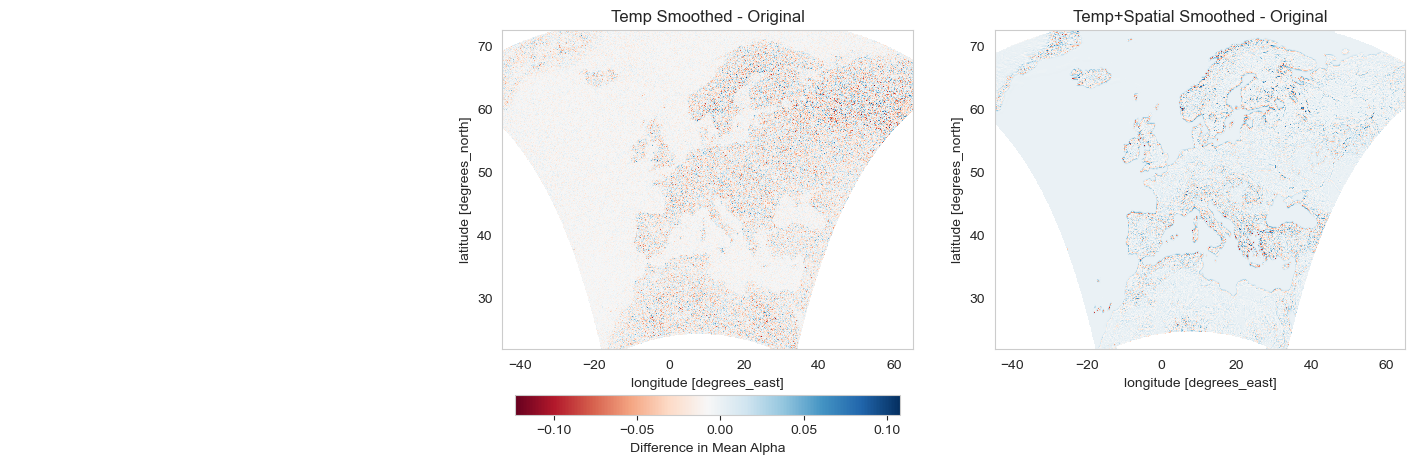

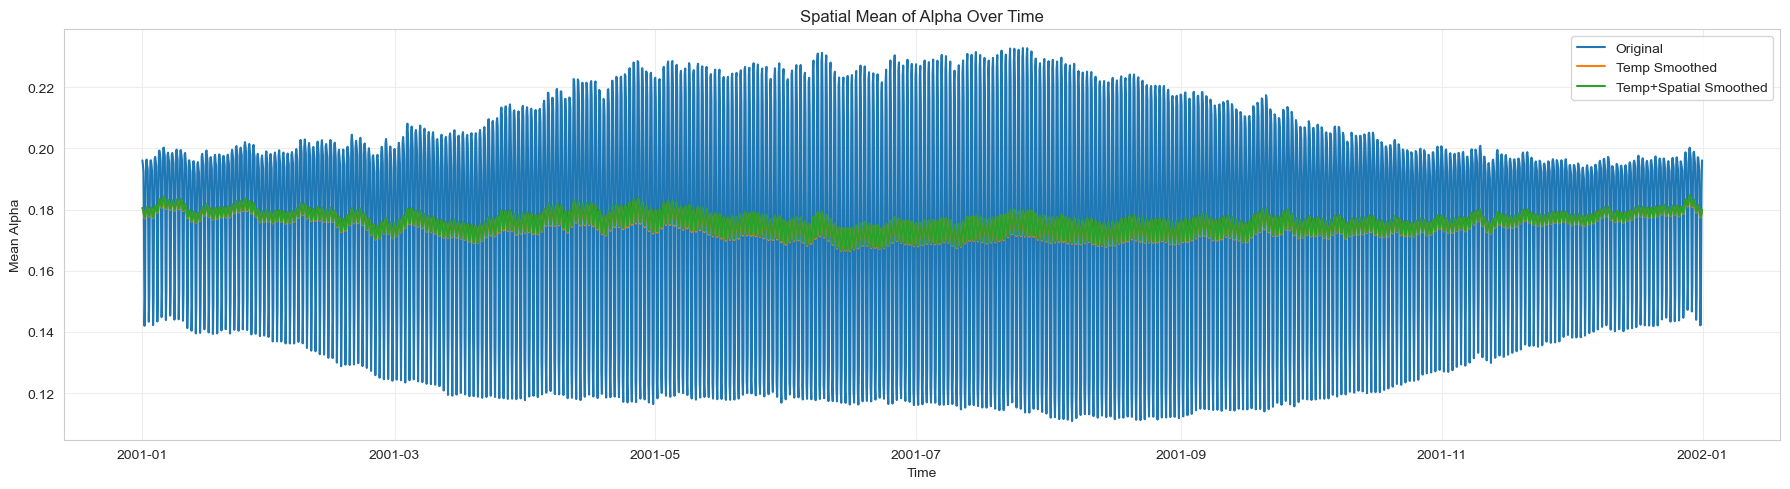

In [ ]:
# Plot spatial mean maps
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
vmin = min(mean_map.min().item() for mean_map in spatial_mean.values())
vmax = max(mean_map.max().item() for mean_map in spatial_mean.values())

im_list = []
for ax, (label, mean_map) in zip(axes, spatial_mean.items()):
    im = mean_map.plot(
        ax=ax, cmap="viridis", robust=True, vmin=vmin, vmax=vmax, add_colorbar=False
    )
    ax.set_title(f"Temporal Mean: {label}")
    im_list.append(im)

cbar = fig.colorbar(
    im_list[0], ax=axes, orientation="horizontal", fraction=0.05, pad=0.12
)
cbar.set_label("Mean Alpha")
plt.savefig(
    path_figs / "wind_speed_alpha" / "temporal_mean_alpha.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()
# Plot difference in spatial mean between original and smoothed versions
fig_diff, axes_diff = plt.subplots(1, 3, figsize=(18, 5))

# First subplot: empty (for alignment)
axes_diff[0].axis("off")

# Second subplot: Temp Smoothed - Original
diff_temp = spatial_mean["Temp Smoothed"] - spatial_mean["Original"]
im_temp = diff_temp.plot(
    ax=axes_diff[1],
    cmap="RdBu",
    robust=True,
    vmin=diff_temp.min().item(),
    vmax=diff_temp.max().item(),
    add_colorbar=False,
)
axes_diff[1].set_title("Temp Smoothed - Original")

# Third subplot: Temp+Spatial Smoothed - Original
diff_tempspatial = spatial_mean["Temp+Spatial Smoothed"] - spatial_mean["Original"]
im_tempspatial = diff_tempspatial.plot(
    ax=axes_diff[2],
    cmap="RdBu",
    robust=True,
    vmin=diff_tempspatial.min().item(),
    vmax=diff_tempspatial.max().item(),
    add_colorbar=False,
)
axes_diff[2].set_title("Temp+Spatial Smoothed - Original")

# Add a single colorbar for both difference plots
cbar_diff = fig_diff.colorbar(
    im_tempspatial, ax=axes_diff, orientation="horizontal", fraction=0.05, pad=0.12
)
cbar_diff.set_label("Difference in Mean Alpha")
plt.savefig(
    path_figs / "wind_speed_alpha" / "temporal_mean_diff_alpha.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

# Plot temporal mean time series
plt.figure(figsize=(18, 5))
for label, mean_ts in temporal_mean.items():
    plt.plot(da_alpha_cerra.time, mean_ts, label=label)
plt.xlabel("Time")
plt.ylabel("Mean Alpha")
plt.title("Spatial Mean of Alpha Over Time")
plt.legend()
plt.tight_layout()
plt.savefig(
    path_figs / "wind_speed_alpha" / "spatial_mean_alpha.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

### Boxplots

/tmp/ipykernel_34113/1485983153.py:38: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
/home/yhaddad/.conda/envs/bias_correction_2024/lib/python3.11/site-packages/IPython/core/pylabtools.py:152: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


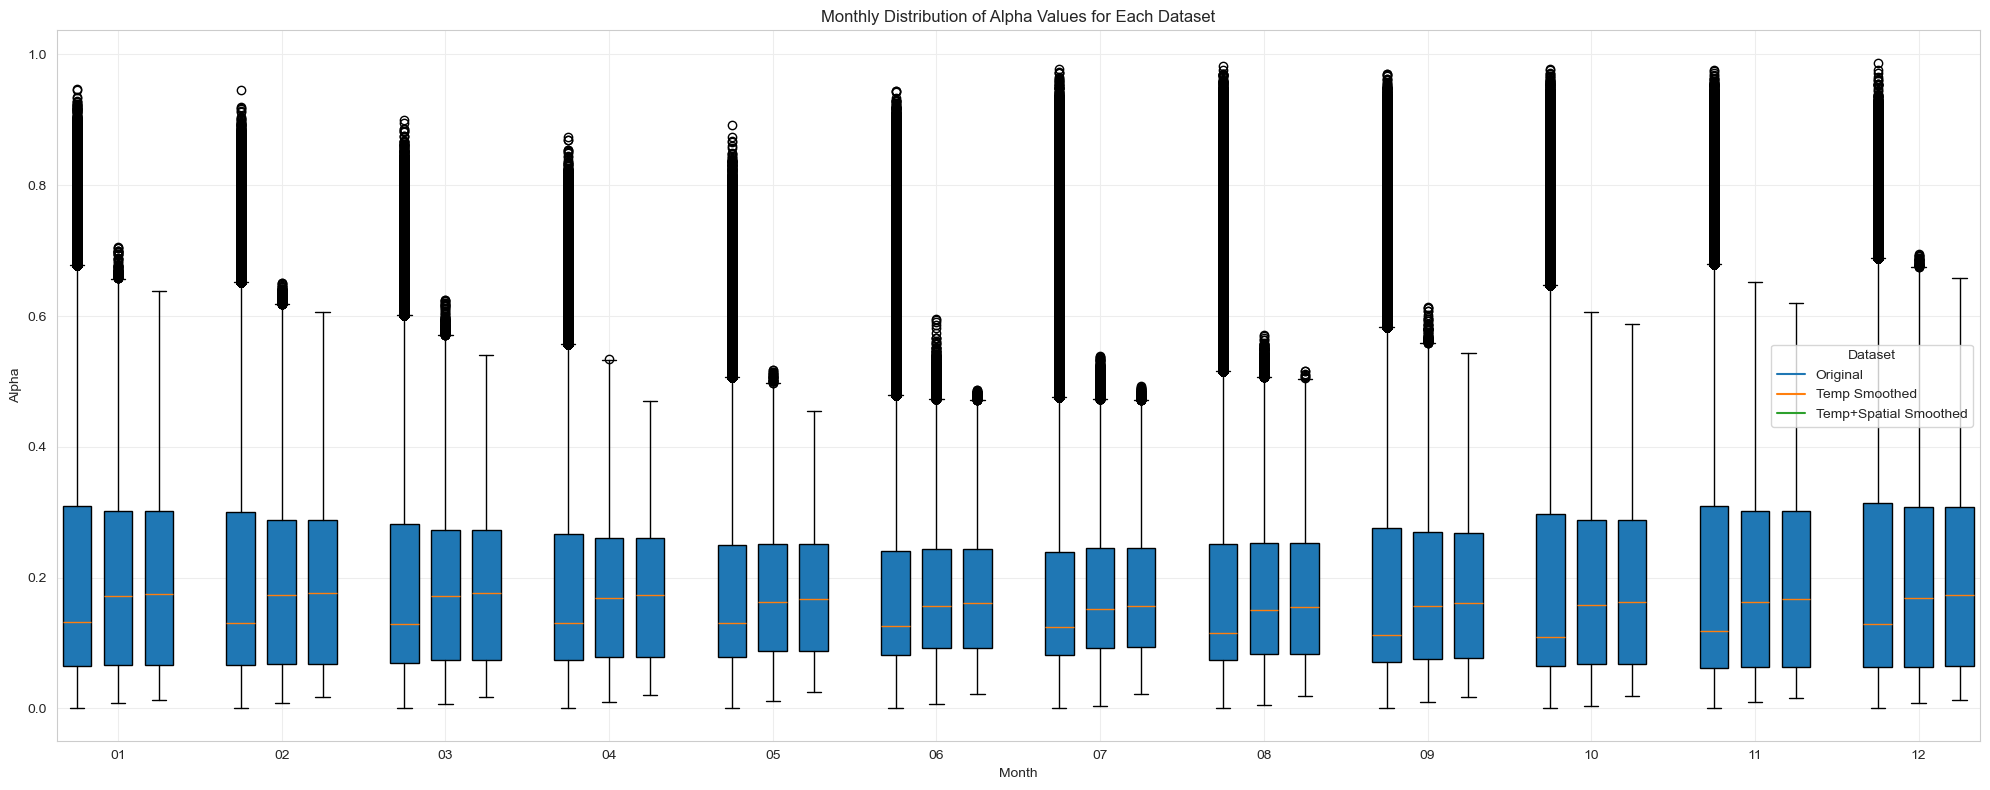

In [ ]:
# Prepare data for boxplot: extract alpha values for each month and dataset

months = np.arange(1, 13)
boxplot_data = []
boxplot_labels = []

for month in months:
    for label, ds in zip(
        ["Original", "Temp Smoothed", "Temp+Spatial Smoothed"],
        [
            da_alpha_cerra,
            da_alpha_temp_smoothed_cerra,
            da_alpha_tempspatial_smoothed_cerra,
        ],
    ):
        # Select all alpha values for the given month (across all years and grid points)
        month_mask = ds.time.dt.month == month
        alpha_vals = ds.alpha.sel(time=month_mask).values.ravel()
        # Remove NaNs
        alpha_vals = alpha_vals[~np.isnan(alpha_vals)]
        boxplot_data.append(alpha_vals)
        boxplot_labels.append(f"{label}\n{month:02d}")

plt.figure(figsize=(20, 8))
positions = []
for i in range(12):
    positions.extend([i * 4 + 1, i * 4 + 2, i * 4 + 3])
plt.boxplot(boxplot_data, positions=positions, widths=0.7, patch_artist=True)

# Set x-ticks in the center of each group of 3
plt.xticks([i * 4 + 2 for i in range(12)], [f"{month:02d}" for month in months])
plt.xlabel("Month")
plt.ylabel("Alpha")
plt.title("Monthly Distribution of Alpha Values for Each Dataset")
# Add legend manually
colors = ["C0", "C1", "C2"]
for i, color in enumerate(colors):
    plt.plot(
        [], c=color, label=["Original", "Temp Smoothed", "Temp+Spatial Smoothed"][i]
    )
plt.legend(title="Dataset")
plt.tight_layout()
plt.show()

# Validate alpha computation

## 2025-07-16

In [ ]:
# Metrics for CERRA alpha extrapolation from 100m
df_cerra_100m = pd.DataFrame(
    {
        "Method": ["alpha", "alpha_temp_smoothed", "alpha_tempspatial_smoothed"],
        "bias": [0.0165, 0.0105, 0.0118],
        "mae": [0.2993, 0.3213, 0.3229],
        "mse": [0.2359, 0.2493, 0.2521],
        "rmse": [0.4857, 0.4993, 0.5021],
    }
)

# Metrics for CERRA alpha extrapolation from 10m
df_cerra_10m = pd.DataFrame(
    {
        "Method": ["alpha", "alpha_temp_smoothed", "alpha_tempspatial_smoothed"],
        "bias": [0.2493, 0.2214, 0.23],
        "mae": [1.2178, 1.2643, 1.2671],
        "mse": [3.5216, 3.0992, 3.089],
        "rmse": [1.8766, 1.7604, 1.7576],
    }
)

# Metrics for CORDEX alpha extrapolation from 10m
df_cordex_10m = pd.DataFrame(
    {
        "Method": ["alpha", "alpha_temp_smoothed", "alpha_tempspatial_smoothed"],
        "bias": [0.3354, 0.3106, 0.3149],
        "mae": [1.168, 1.1761, 1.1821],
        "mse": [3.2579, 2.6963, 2.6932],
        "rmse": [1.805, 1.642, 1.6411],
    }
)

print("Metrics for CERRA alpha extrapolation from 100m, based on year 2021")
display(df_cerra_100m)
print("Metrics for CERRA alpha extrapolation from 10m, based on year 2021")
display(df_cerra_10m)
print("Metrics for CORDEX alpha extrapolation from 10m, based on year 2021-2030")
display(df_cordex_10m)

Metrics for CERRA alpha extrapolation from 100m, based on year 2021


,Method,bias,mae,mse,rmse
0,alpha,0.0165,0.2993,0.2359,0.4857
1,alpha_temp_smoothed,0.0105,0.3213,0.2493,0.4993
2,alpha_tempspatial_smoothed,0.0118,0.3229,0.2521,0.5021


Metrics for CERRA alpha extrapolation from 10m, based on year 2021


,Method,bias,mae,mse,rmse
0,alpha,0.2493,1.2178,3.5216,1.8766
1,alpha_temp_smoothed,0.2214,1.2643,3.0992,1.7604
2,alpha_tempspatial_smoothed,0.2300,1.2671,3.0890,1.7576


Metrics for CORDEX alpha extrapolation from 10m, based on year 2021-2030


,Method,bias,mae,mse,rmse
0,alpha,0.3354,1.1680,3.2579,1.8050
1,alpha_temp_smoothed,0.3106,1.1761,2.6963,1.6420
2,alpha_tempspatial_smoothed,0.3149,1.1821,2.6932,1.6411


In [ ]:
# CERRA 10m -> 100m (2021)
df_cerra_10m_100m = pd.DataFrame(
    {
        "Method": ["alpha", "alpha_temp_smoothed", "alpha_tempspatial_smoothed"],
        "bias": [0.0939, 0.0922, 0.0983],
        "mae": [0.7966, 0.899, 0.9079],
        "mse": [1.6676, 1.6887, 1.7159],
        "rmse": [1.2914, 1.2995, 1.3099],
    }
)

# CERRA 10m -> 150m (2021)
df_cerra_10m_150m = pd.DataFrame(
    {
        "Method": ["alpha", "alpha_temp_smoothed", "alpha_tempspatial_smoothed"],
        "bias": [0.1219, 0.1037, 0.1097],
        "mae": [1.0311, 1.1696, 1.1783],
        "mse": [2.751, 2.7755, 2.8087],
        "rmse": [1.6586, 1.666, 1.6759],
    }
)

# CORDEX 10m -> 100m (2021-2030)
df_cordex_10m_100m = pd.DataFrame(
    {
        "Method": ["alpha", "alpha_temp_smoothed", "alpha_tempspatial_smoothed"],
        "bias": [0.1116, 0.1101, 0.1147],
        "mae": [0.7292, 0.7987, 0.8105],
        "mse": [1.3631, 1.2878, 1.3141],
        "rmse": [1.1675, 1.1348, 1.1463],
    }
)

# CORDEX 10m -> 150m (2021-2030)
df_cordex_10m_150m = pd.DataFrame(
    {
        "Method": ["alpha", "alpha_temp_smoothed", "alpha_tempspatial_smoothed"],
        "bias": [0.1407, 0.1276, 0.1311],
        "mae": [0.9541, 1.0496, 1.0612],
        "mse": [2.355, 2.224, 2.2531],
        "rmse": [1.5346, 1.4913, 1.501],
    }
)

print("CERRA 10m -> 100m (2021)")
display(df_cerra_10m_100m)
print("CERRA 10m -> 150m (2021)")
display(df_cerra_10m_150m)
print("CORDEX 10m -> 100m (2021-2030)")
display(df_cordex_10m_100m)
print("CORDEX 10m -> 150m (2021-2030)")
display(df_cordex_10m_150m)

CERRA 10m -> 100m (2021)


,Method,bias,mae,mse,rmse
0,alpha,0.0939,0.7966,1.6676,1.2914
1,alpha_temp_smoothed,0.0922,0.8990,1.6887,1.2995
2,alpha_tempspatial_smoothed,0.0983,0.9079,1.7159,1.3099


CERRA 10m -> 150m (2021)


,Method,bias,mae,mse,rmse
0,alpha,0.1219,1.0311,2.7510,1.6586
1,alpha_temp_smoothed,0.1037,1.1696,2.7755,1.6660
2,alpha_tempspatial_smoothed,0.1097,1.1783,2.8087,1.6759


CORDEX 10m -> 100m (2021-2030)


,Method,bias,mae,mse,rmse
0,alpha,0.1116,0.7292,1.3631,1.1675
1,alpha_temp_smoothed,0.1101,0.7987,1.2878,1.1348
2,alpha_tempspatial_smoothed,0.1147,0.8105,1.3141,1.1463


CORDEX 10m -> 150m (2021-2030)


,Method,bias,mae,mse,rmse
0,alpha,0.1407,0.9541,2.3550,1.5346
1,alpha_temp_smoothed,0.1276,1.0496,2.2240,1.4913
2,alpha_tempspatial_smoothed,0.1311,1.0612,2.2531,1.5010


# Mean alpha vs Median Alpha

## Plots

In [14]:
# Compute spatial mean (mean over time for each grid point)
spatial_mean = {
    "Mean": da_alpha_cerra.alpha.mean(dim="time"),
    "Median": da_alpha_cerra_median.alpha.mean(dim="time"),
}
# Compute temporal mean (mean over space for each timestep)
temporal_mean = {
    "Mean": da_alpha_cerra.alpha.mean(dim=["lat", "lon"]),
    "Median": da_alpha_cerra_median.alpha.mean(dim=["lat", "lon"]),
}

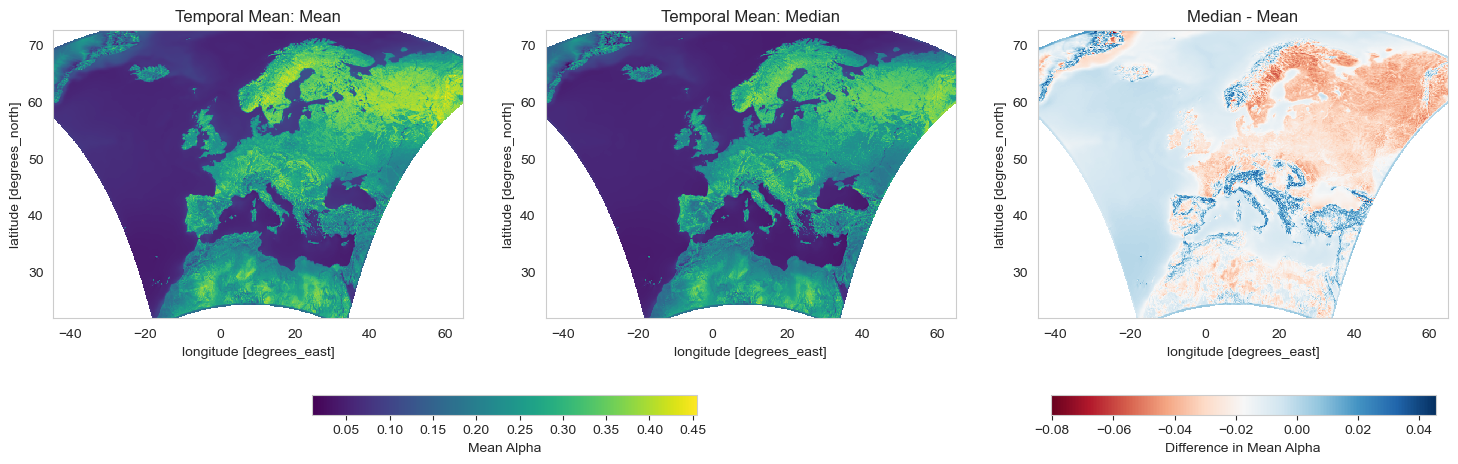

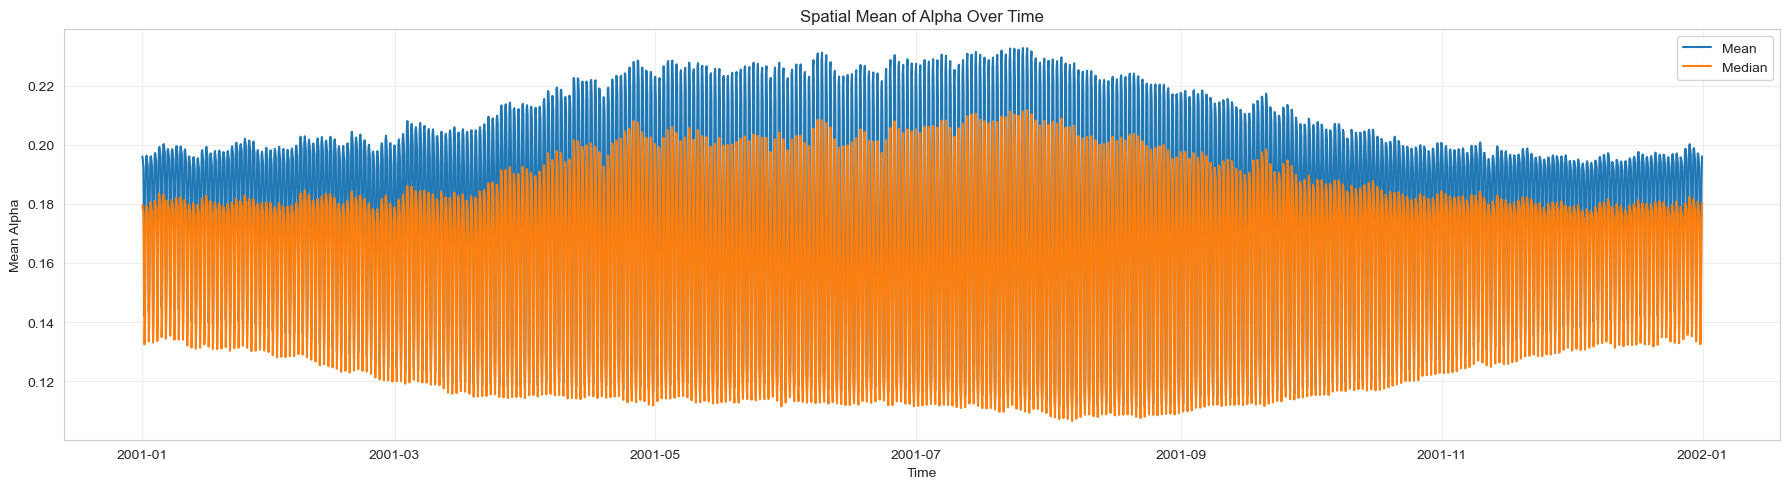

In [21]:
# Plot spatial mean maps
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
vmin = min(mean_map.min().item() for mean_map in spatial_mean.values())
vmax = max(mean_map.max().item() for mean_map in spatial_mean.values())

im_list = []
for ax, (label, mean_map) in zip(axes, spatial_mean.items()):
    im = mean_map.plot(
        ax=ax, cmap="viridis", robust=True, vmin=vmin, vmax=vmax, add_colorbar=False
    )
    ax.set_title(f"Temporal Mean: {label}")
    im_list.append(im)

cbar = fig.colorbar(
    im_list[0], ax=axes[:2], orientation="horizontal", fraction=0.05, pad=0.2
)
cbar.set_label("Mean Alpha")

# Second subplot:  - Mean
diff_temp = spatial_mean["Median"] - spatial_mean["Mean"]
im_temp = diff_temp.plot(
    ax=axes[2],
    cmap="RdBu",
    robust=True,
    vmin=diff_temp.min().item(),
    vmax=diff_temp.max().item(),
    add_colorbar=False,
)
axes[2].set_title("Median - Mean")

# Add a single colorbar for both difference plots
cbar_diff = fig.colorbar(
    im_temp, ax=axes[2], orientation="horizontal", fraction=0.05, pad=0.2
)
cbar_diff.set_label("Difference in Mean Alpha")
plt.show()

# Plot temporal mean time series
plt.figure(figsize=(18, 5))
for label, mean_ts in temporal_mean.items():
    plt.plot(da_alpha_cerra.time, mean_ts, label=label)
plt.xlabel("Time")
plt.ylabel("Mean Alpha")
plt.title("Spatial Mean of Alpha Over Time")
plt.legend()
plt.tight_layout()
plt.show()

## Validation on climate model

In [8]:
climate_model_chain = "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1"
climate_scenario = "rcp85"
climate_model_bc_path = (
        path_data_processed
        / "cordex_processed"
        / f"{climate_model_chain}_{climate_scenario}"
        / "bias_corrected"
        / "3hr"
    )

ds_sfcWind_climate_model = ClimateModelData(
    climate_model_bc_path / "sfcWind.zarr",
    chunks="auto",
    extent=None,
    load=False,
    drop_leap_days=True,
)
ds_sfcWind_climate_model.ds_data = ds_sfcWind_climate_model.ds_data.rename(
    {"sfcWind": "ws"}
).sel(time=slice("2021", "2030"))

ds_ws_100m_climate_model = ClimateModelData(
    climate_model_bc_path / "wind100m.zarr",
    chunks="auto",
    extent=None,
    load=False,
    drop_leap_days=True,
)

ds_ws_100m_climate_model.ds_data = ds_ws_100m_climate_model.ds_data.rename(
    {"wind100m": "ws"}
).sel(time=slice("2021", "2030"))

In [9]:
# Index da_alpha cyclically
da_alpha_cerra_tiled = (
    da_alpha_cerra
    .isel(
        time=(
            np.arange(len(ds_ws_100m_climate_model.ds_data.time))
            % len(da_alpha_cerra.time)
        )
    )
    .assign_coords(time=ds_ws_100m_climate_model.ds_data.time)
).chunk(BC_SUBDAILY_CHUNKS)

In [10]:
# Index da_alpha cyclically
da_alpha_cerra_median_tiled = (
    da_alpha_cerra_median
    .isel(
        time=(
            np.arange(len(ds_ws_100m_climate_model.ds_data.time))
            % len(da_alpha_cerra_median.time)
        )
    )
    .assign_coords(time=ds_ws_100m_climate_model.ds_data.time)
).chunk(BC_SUBDAILY_CHUNKS)

In [11]:
da_ws_100_climate_model = ds_ws_100m_climate_model.ds_data["ws"].sel(lat=47.5, lon=8.5, method="nearest")
jan1_ws_100_climate_model = da_ws_100_climate_model.sel(time=(da_ws_100_climate_model.time.dt.month == 1) & (da_ws_100_climate_model.time.dt.day == 1))

da_ws_10_climate_model = ds_sfcWind_climate_model.ds_data["ws"].sel(lat=47.5, lon=8.5, method="nearest")
jan1_ws_10_climate_model = da_ws_10_climate_model.sel(time=(da_ws_10_climate_model.time.dt.month == 1) & (da_ws_10_climate_model.time.dt.day == 1))

In [12]:
hours = np.unique(jan1_ws_10_climate_model.time.dt.hour.values)

In [13]:
with ProgressBar(dt=1):
    y_pred_climate_model_mean_alpha = jan1_ws_10_climate_model * (100 / 10) ** da_alpha_cerra_tiled.alpha.sel(lat=47.5, lon=8.5, method="nearest").sel(time=jan1_ws_10_climate_model.time).compute()
    y_pred_climate_model_median_alpha = jan1_ws_10_climate_model * (100 / 10) ** da_alpha_cerra_median_tiled.alpha.sel(lat=47.5, lon=8.5, method="nearest").sel(time=jan1_ws_10_climate_model.time).compute()
for i, hour in enumerate(hours):
    print(f"Evaluating hour {int(hour)}")
    y_true = jan1_ws_100_climate_model.sel(time=(jan1_ws_100_climate_model.time.dt.hour == hour)).values
    y_pred_climate_model_mean_alpha_hour = y_pred_climate_model_mean_alpha.sel(time=(jan1_ws_100_climate_model.time.dt.hour == hour)).values
    ss_res = np.sum((y_true - y_pred_climate_model_mean_alpha_hour) ** 2)
    ss_tot = np.sum((y_true - y_true.mean()) ** 2)
    r2 = 1 - ss_res / ss_tot if ss_tot != 0 else np.nan
    mse = np.mean((y_true - y_pred_climate_model_mean_alpha_hour) ** 2)
    bias = np.mean(y_true - y_pred_climate_model_mean_alpha_hour)

    print(f"Mean alpha: R²: {r2:.4f}, MSE: {mse:.6f}, Bias: {bias:.6f}")

    y_pred_climate_model_median_alpha_hour = y_pred_climate_model_median_alpha.sel(time=(jan1_ws_100_climate_model.time.dt.hour == hour)).values
    ss_res = np.sum((y_true - y_pred_climate_model_median_alpha_hour) ** 2)
    ss_tot = np.sum((y_true - y_true.mean()) ** 2)
    r2 = 1 - ss_res / ss_tot if ss_tot != 0 else np.nan
    mse = np.mean((y_true - y_pred_climate_model_median_alpha_hour) ** 2)
    bias = np.mean(y_true - y_pred_climate_model_median_alpha_hour)

    print(f"Median alpha: R²: {r2:.4f}, MSE: {mse:.6f}, Bias: {bias:.6f}")
    print("-----\n")

[########################################] | 100% Completed | 98.12 s
[########################################] | 100% Completed | 159.19 s
Evaluating hour 0
Mean alpha: R²: 0.9532, MSE: 0.590741, Bias: -0.226827
Median alpha: R²: 0.9689, MSE: 0.392320, Bias: 0.120372
-----

Evaluating hour 3
Mean alpha: R²: 0.7592, MSE: 2.558156, Bias: -1.323530
Median alpha: R²: 0.9732, MSE: 0.284557, Bias: -0.388610
-----

Evaluating hour 6
Mean alpha: R²: 0.7388, MSE: 2.607349, Bias: -1.082587
Median alpha: R²: 0.8782, MSE: 1.215683, Bias: -0.460746
-----

Evaluating hour 9
Mean alpha: R²: 0.8033, MSE: 1.234460, Bias: -0.624858
Median alpha: R²: 0.9184, MSE: 0.512218, Bias: 0.010975
-----

Evaluating hour 12
Mean alpha: R²: 0.9982, MSE: 0.027317, Bias: 0.050378
Median alpha: R²: 0.9914, MSE: 0.130816, Bias: -0.259129
-----

Evaluating hour 15
Mean alpha: R²: 0.9668, MSE: 0.361140, Bias: -0.375850
Median alpha: R²: 0.9910, MSE: 0.097563, Bias: -0.052241
-----

Evaluating hour 18
Mean alpha: R²: 0.8

## Compare wind power generation

In [12]:
ds_wind_power_mean_alpha = xr.open_dataset("wind_power_agg_CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp45_E-126_7580.nc")
ds_wind_power_median_alpha = xr.open_dataset(path_data_processed / "energy" / "europe" / "wind_power" / "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp45" / "wind_power_agg_CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp45_E-126_7580.nc")

ds_wind_power_rcp_26 = xr.open_dataset(path_data_processed / "energy" / "europe" / "wind_power" / "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp26" / "wind_power_agg_CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp26_E-126_7580.nc")
ds_wind_power_rcp_85 = xr.open_dataset(path_data_processed / "energy" / "europe" / "wind_power" / "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85" / "wind_power_agg_CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85_E-126_7580.nc")

In [32]:
var = list(ds_wind_power_rcp_26.data_vars.keys())[0]

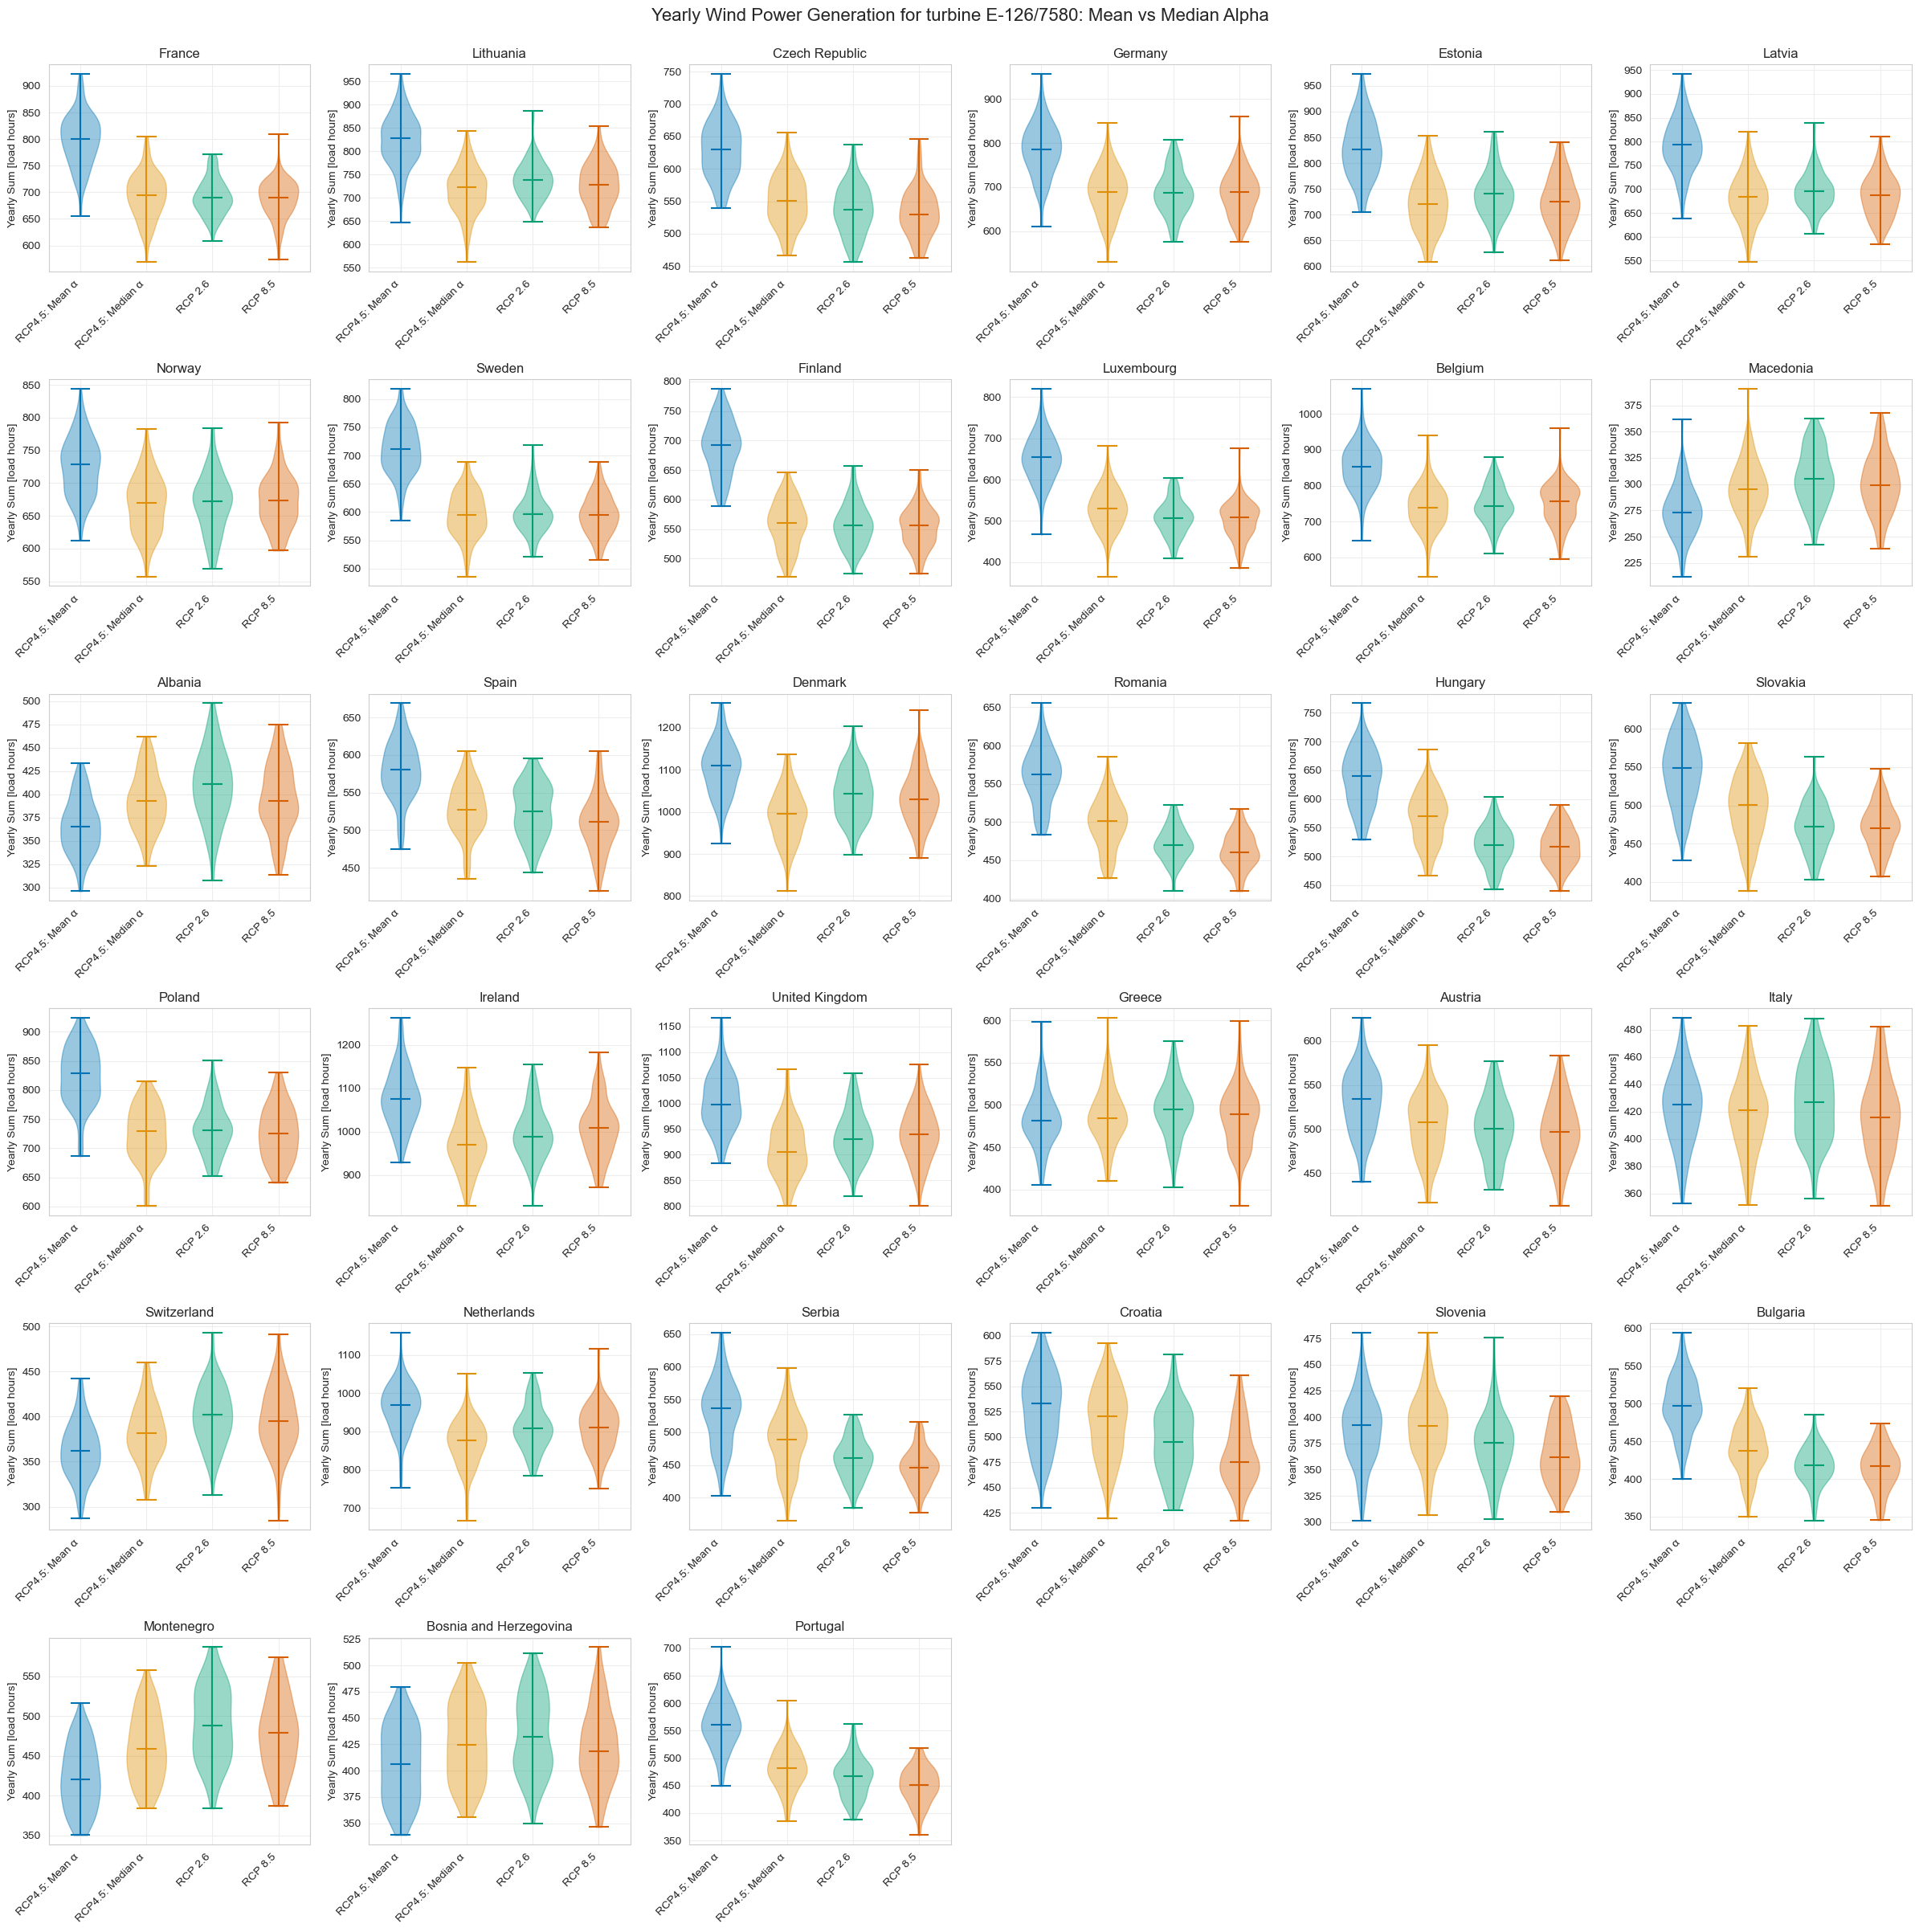

In [48]:
sns.set_palette("colorblind")
# Compute yearly sums for both datasets
yearly_sum_mean = ds_wind_power_mean_alpha[var].resample(time="YE").sum()
yearly_sum_median = ds_wind_power_median_alpha[var].resample(time="YE").sum()
yearly_sum_rcp_26 = ds_wind_power_rcp_26[var].resample(time="YE").sum()
yearly_sum_rcp_85 = ds_wind_power_rcp_85[var].resample(time="YE").sum()

# Get list of countries
countries = ds_wind_power_mean_alpha.country.values

# Create figure with subplots (one per country)
n_countries = len(countries)
cols = 6
rows = int(np.ceil(n_countries / cols))

fig, axes = plt.subplots(rows, cols, figsize=(cols * 4, rows * 4), squeeze=False)
axes_flat = axes.ravel()

for i, country in enumerate(countries):
    ax = axes_flat[i]

    # Extract data for this country
    data_mean = yearly_sum_mean.sel(country=country).values
    data_median = yearly_sum_median.sel(country=country).values
    data_rcp_26 = yearly_sum_rcp_26.sel(country=country).values
    data_rcp_85 = yearly_sum_rcp_85.sel(country=country).values

    # Create violin plots with seaborn
    data_to_plot = [data_mean, data_median, data_rcp_26, data_rcp_85]
    for j, (data, color) in enumerate(zip(data_to_plot, colors[:4]), start=1):
        parts = ax.violinplot([data], positions=[j], showmeans=False, showmedians=True, widths=0.6)
        for pc in parts['bodies']:
            pc.set_facecolor(color)
            pc.set_edgecolor(color)
            pc.set_alpha(0.4)

    ax.set_xticks([1, 2, 3, 4])
    ax.set_xticklabels(['RCP4.5: Mean α', 'RCP4.5: Median α', 'RCP 2.6', 'RCP 8.5'], rotation=45, ha='right')
    ax.set_title(country)
    ax.set_ylabel('Yearly Sum [load hours]')
    # ax.grid(axis='y', alpha=0.3)

# Hide any empty subplots
for j in range(n_countries, rows * cols):
    axes_flat[j].axis('off')

fig.suptitle(f'Yearly Wind Power Generation for turbine {var.replace("_", "/")}: Mean vs Median Alpha', fontsize=16, y=1.00)
fig.tight_layout()
plt.show()

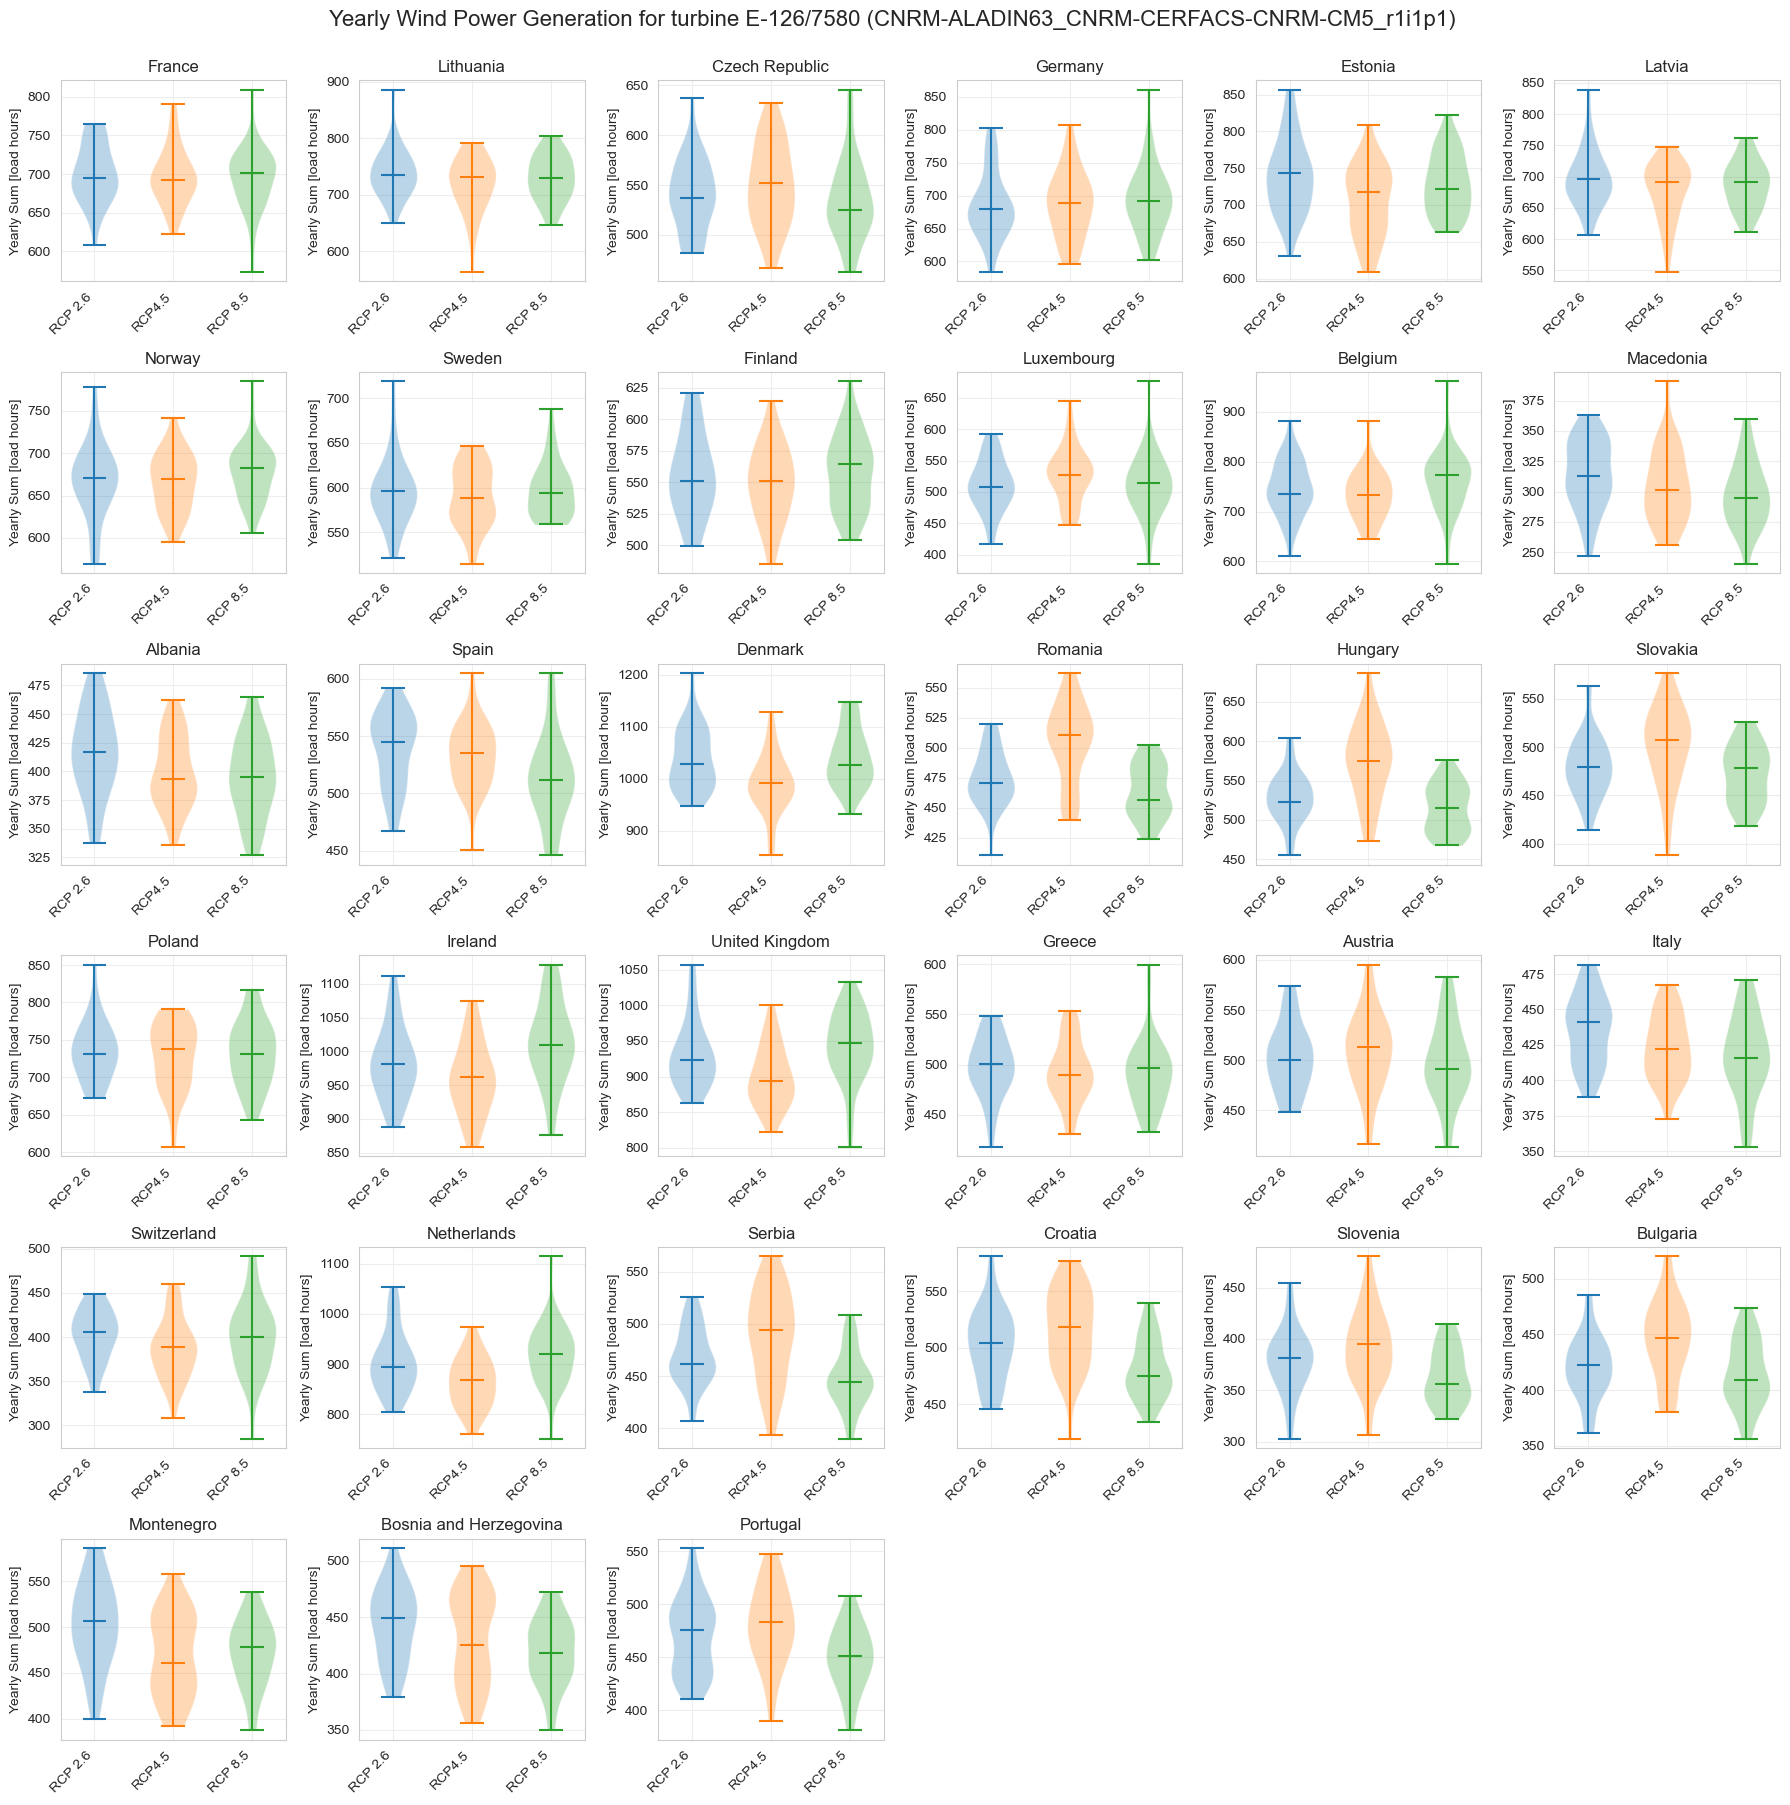

In [43]:
colors = sns.color_palette("colorblind")
# Compute yearly sums for both datasets
yearly_sum_median = ds_wind_power_median_alpha[var].resample(time="YE").sum().sel(time=slice("2018", "2052"))
yearly_sum_rcp_26 = ds_wind_power_rcp_26[var].resample(time="YE").sum().sel(time=slice("2018", "2052"))
yearly_sum_rcp_85 = ds_wind_power_rcp_85[var].resample(time="YE").sum().sel(time=slice("2018", "2052"))

# Get list of countries
countries = ds_wind_power_median_alpha.country.values

# Create figure with subplots (one per country)
n_countries = len(countries)
cols = 6
rows = int(np.ceil(n_countries / cols))

fig, axes = plt.subplots(rows, cols, figsize=(cols * 3, rows * 3), squeeze=False)
axes_flat = axes.ravel()

for i, country in enumerate(countries):
    ax = axes_flat[i]

    # Extract data for this country
    data_rcp_26 = yearly_sum_rcp_26.sel(country=country).values
    data_median = yearly_sum_median.sel(country=country).values
    data_rcp_85 = yearly_sum_rcp_85.sel(country=country).values

    # Create violin plots with seaborn
    data_to_plot = [data_rcp_26, data_median, data_rcp_85]
    for j, (data, color) in enumerate(zip(data_to_plot, [colors[2], colors[1], colors[3]]), start=1):
        parts = ax.violinplot([data], positions=[j], showmeans=False, showmedians=True, widths=0.6)
        # for pc in parts['bodies']:
        #     pc.set_facecolor(color)
        #     pc.set_edgecolor(color)
        #     pc.set_alpha(0.4)

    ax.set_xticks([1, 2, 3])
    ax.set_xticklabels(['RCP 2.6', 'RCP4.5', 'RCP 8.5'], rotation=45, ha='right')
    ax.set_title(country)
    ax.set_ylabel('Yearly Sum [load hours]')
    # ax.grid(axis='y', alpha=0.3)

# Hide any empty subplots
for j in range(n_countries, rows * cols):
    axes_flat[j].axis('off')

fig.suptitle('Yearly Wind Power Generation for turbine E-126/7580 (CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1) ', fontsize=16, y=1.00)
fig.tight_layout()
plt.show()